# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [71]:
# Importe de librerías a utilizar

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
%matplotlib inline


In [73]:
# Escribe aquí tu código para descargar los datos de tus 3 activos elegidos

activos = ["OXY","C","UNH"]

datos = yf.download(
    activos,
    start="2024-01-01",
    end="2026-01-01",
    auto_adjust=True
)

datos.head()

[*********************100%***********************]  3 of 3 completed


Price           Close                              High             \
Ticker              C        OXY         UNH          C        OXY   
Date                                                                 
2024-01-02  49.015568  57.020275  508.214783  49.117222  57.865371   
2024-01-03  49.570045  57.552021  510.749573  50.244656  57.722940   
2024-01-04  49.690182  56.137192  513.943970  50.595823  57.969817   
2024-01-05  50.207691  55.966278  506.367889  50.521890  56.564493   
2024-01-08  49.911961  55.330074  505.557587  49.985892  55.339568   

Price                         Low                              Open  \
Ticker             UNH          C        OXY         UNH          C   
Date                                                                  
2024-01-02  508.516265  47.305935  56.877845  496.275925  47.407589   
2024-01-03  515.234826  48.267030  56.441050  508.346687  49.209637   
2024-01-04  517.317385  49.588527  56.013753  511.663643  49.828798   
2024-01-05  515.432716  49.801074  55.633938  502.928507  49.930451   
2024-01-08  509.072311  48.997079  54.428004  497.529255  49.893481   

Price                                Volume                     
Ticker            OXY         UNH         C       OXY      UNH  
Date                                                            
2024-01-02  57.143717  496.436156  24784900   7456200  3415700  
2024-01-03  56.621466  511.701238  30897600   7269300  2891400  
2024-01-04  57.770413  513.548224  23714300   9423300  2994400  
2024-01-05  56.498026  515.432716  17782200   8016800  2815400  
2024-01-08  55.045211  508.271387  17359500  10343500  2648900

## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

In [44]:

# 1. Extraer los precios de cierre

cierre = datos["Close"]

cierre.head()

Ticker,C,OXY,UNH
Date,,,
2024-01-02,49.015568,57.020275,508.214783
2024-01-03,49.570045,57.552021,510.749573
2024-01-04,49.690182,56.137192,513.943970
2024-01-05,50.207691,55.966278,506.367889
2024-01-08,49.911961,55.330074,505.557587


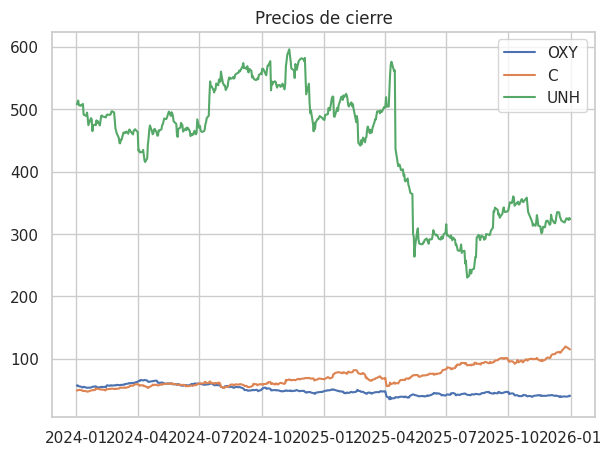

In [45]:
# 2. Graficar precios originales

plt.figure(figsize=(7,5))

for activo in activos:
    plt.plot(cierre.index,cierre[activo],label=activo)

plt.title("Precios de cierre")
plt.legend()
plt.show()

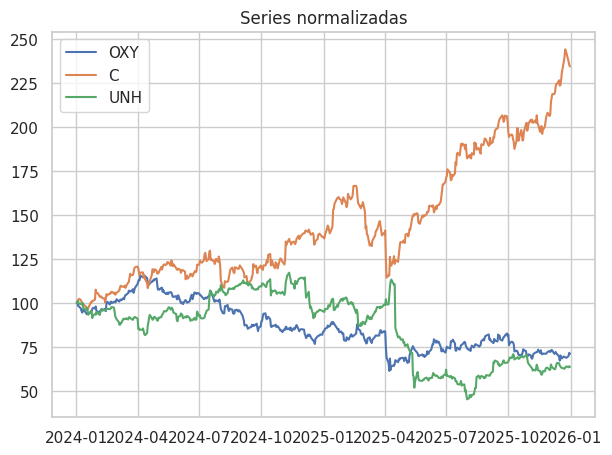

In [61]:
# 3. Normalizar y graficar en base 100

normalizado = cierre / cierre.iloc[0] * 100

plt.figure(figsize=(7,5))

for activo in activos:
    plt.plot(normalizado.index,normalizado[activo],label=activo)

plt.title("Series normalizadas")
plt.legend()
plt.show()

## Interpretación Paso 2

El gráfico de precios originales muestra los valores absolutos de cada activo, mientras que el gráfico normalizado permite comparar el crecimiento relativo desde una misma base de referencia.

Metodológicamente el gráfico normalizado es más adecuado para comparar desempeño, ya que elimina las diferencias de precio inicial entre los activos y permite observar cuál obtuvo una mejor rentabilidad porcentual durante el período analizado.

## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

In [62]:
# 1. Calcular rendimientos

rendimientos = cierre.pct_change().dropna()

In [67]:
volatilidad = rendimientos.std()

volatilidad

,0
Ticker,
C,0.018206
OXY,0.018912
UNH,0.024345


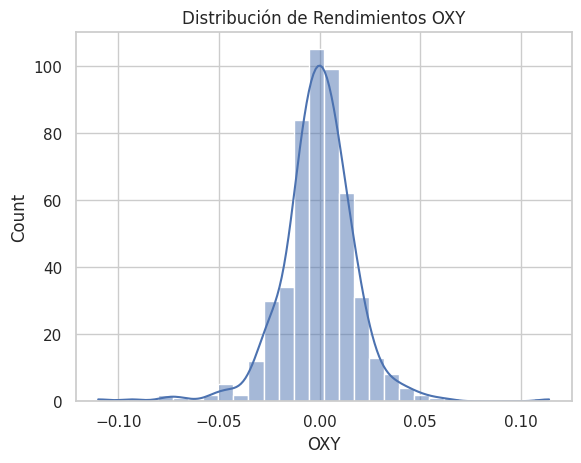

In [68]:
# 2. Histograma con el activo más volátil

sns.histplot(
    rendimientos["OXY"],
    bins=30,
    kde=True
)

plt.title("Distribución de Rendimientos OXY")
plt.show()

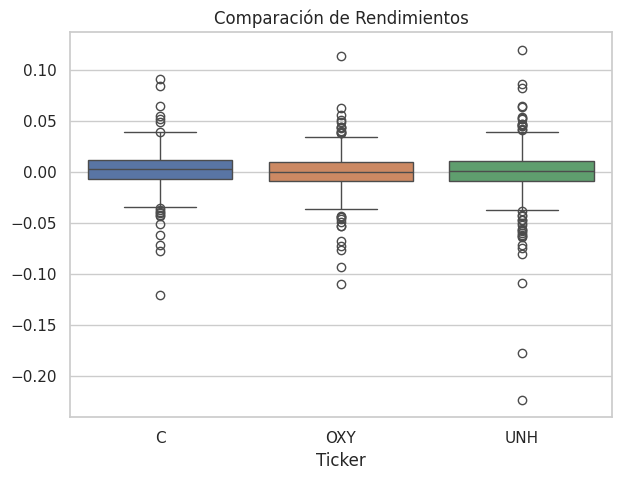

In [66]:
# 3. Boxplot comparativo de rendimientos

plt.figure(figsize=(7,5))

sns.boxplot(data=rendimientos)

plt.title("Comparación de Rendimientos")
plt.show()

## Interpretación Paso 3

De acuerdo a lo evidenciado el activo con mayor dispersión presenta una mayor volatilidad y por lo tanto un mayor nivel de riesgo.

Los valores atípicos representan días con movimientos excepcionales del mercado, generalmente asociados a noticias corporativas, resultados financieros o eventos macroeconómicos relevantes.

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

In [52]:
# 1. Calcular matriz de correlación

corr = rendimientos.corr()

corr

Ticker,C,OXY,UNH
Ticker,,,
C,1.000000,0.353528,0.100215
OXY,0.353528,1.000000,0.014314
UNH,0.100215,0.014314,1.000000


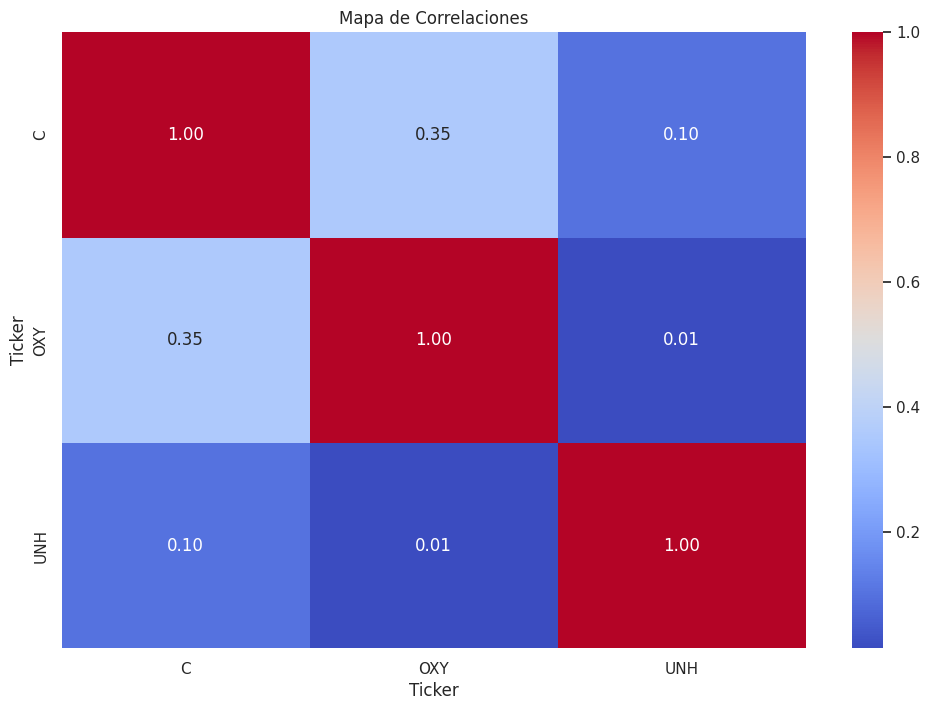

In [69]:
# 2. Dibujar el Heatmap utilizando Seaborn

plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Mapa de Correlaciones")

plt.show()

## Interpretación Paso 4

La matriz de correlación permite identificar qué activos tienden a moverse de forma similar.

Para diversificar un portafolio resulta conveniente seleccionar activos que tengan correlaciones más bajas, ya que esto puede reducir el riesgo conjunto de la inversión.

## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [37]:
# Generar resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)

In [38]:
resumen = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})

resumen

,Media,Mediana,Desviación estándar,Mínimo,Máximo
Ticker,,,,,
C,0.001869,0.002579,0.018206,-0.121377,0.091543
OXY,-0.000500,-0.000176,0.018912,-0.110075,0.114096
UNH,-0.000591,0.000348,0.024345,-0.223797,0.119784


## Conclusión para el inversionista

Los resultados permiten comparar la rentabilidad promedio, volatilidad y riesgo de los activos analizados.

El activo con la mayor media de rendimiento ofrece un mayor potencial de retorno, mientras que el activo con la menor desviación estándar presenta un comportamiento más estable.

La decisión de inversión debe considerar simultáneamente rentabilidad esperada, riesgo y correlación, buscando un equilibrio adecuado entre crecimiento y diversificación.